# I will use the following notebook to demonstrate different steps in preprocessing

## These steps will include:

### 1) Slice timing correction
### 2) Motion correction
### 3) Coregistration
### 4) Spatial and temporal filtering

In [2]:
import os
from glob import glob

# Import new things that we'll need
import pandas as pd
import numpy as np
import nipype.interfaces.afni as afni
import nipype.interfaces.fsl as fsl
import nipype.interfaces.freesurfer as fs
from nipype.interfaces.utility import Function
import seaborn as sns
import nibabel as nb
import json
import nipype.interfaces.io as nio
import nipype.pipeline.engine as pe 
import matplotlib.pyplot as plt

%matplotlib inline

### I next want to get a list of all of my functional files

In [3]:
sid = ['021']
base_dir = f'/home/mali092/Mattfeld_PSB6351'
work_dir = f'/scratch/classroom/psb6351/mali092/Mattfeld_PSB6351'
func_dir = os.path.join(base_dir, f'dset/sub-{sid[0]}/ses-S1/func')
fmap_dir = os.path.join(base_dir, f'dset/sub-{sid[0]}/ses-S1/fmap')
fs_dir = os.path.join(base_dir, 'derivatives', 'freesurfer')

# Get a list of my study task json and nifti converted files
func_json = sorted(glob(func_dir + '/*.json'))
func_files = sorted(glob(func_dir + '/*.nii.gz'))
fmap_files = sorted(glob(fmap_dir + '/sub-*_dir-*_epi.nii.gz'))

In [4]:
fmap_files[0]

'/home/mali092/Mattfeld_PSB6351/dset/sub-021/ses-S1/fmap/sub-021_acq-dMRI_dir-AP_epi.nii.gz'

In [11]:
#ATM ONLY: Add an unwarping mapnode here using the field maps

 ## Using AP and PA reverse phase-encoded EPI images to estimate
 ## susceptibility distortion with AFNI 3dQwarp

#EXTRA CREDIT FIGURE OUT HOW TO ADD A NODE FOR AFNIS QWARP
#TO UTILIZE THE DISTORTION CORRECTION FIELD MAPS

# EXTRA CREDIT: Susceptibility Distortion Correction Using AFNI 3dQwarp

# EXTRA CREDIT: Susceptibility Distortion Correction Using AFNI 3dQwarp

# Get AP and PA reverse phase-encoded EPI images
fmap_ap = glob(fmap_dir + f'/sub-{sid[0]}_dir-AP_epi.nii.gz')[0]
fmap_pa = glob(fmap_dir + f'/sub-{sid[0]}_dir-PA_epi.nii.gz')[0]

# Estimate susceptibility distortion from AP/PA images
qwarp = pe.Node(
    afni.Qwarp(),
    name='qwarp')

qwarp.inputs.base_file = fmap_ap
qwarp.inputs.in_file = fmap_pa
qwarp.inputs.plusminus = True
qwarp.inputs.outputtype = 'NIFTI_GZ'
qwarp.inputs.out_file = f'sub-{sid[0]}_dir-PA_epi_QW.nii.gz'

qwarp_result = qwarp.run()

# Create MapNode to unwarp all functional runs
unwarp = pe.MapNode(
    afni.NwarpApply(),
    iterfield=['in_file'],
    name='unwarp')

unwarp.inputs.in_file = func_files

# IMPORTANT:
# Use source_warp if the functional runs have the same
# phase-encoding direction as the PA/source image.
# Use base_warp if they have the same phase-encoding
# direction as the AP/base image.

# Example for PA-encoded functional runs:
unwarp.inputs.warp = qwarp_result.outputs.source_warp

# Run distortion correction
unwarp_result = unwarp.run()

print("Qwarp completed.")
print("Unwarped functional runs:")
print(unwarp_result.outputs.out_file)

261026-10:12:53,602 nipype.workflow INFO:
	 [Node] Setting-up "qwarp" in "/tmp/tmpxywmxm_w/qwarp".
261026-10:12:53,606 nipype.workflow INFO:
	 [Node] Executing "qwarp" <nipype.interfaces.afni.preprocess.Qwarp>
261026-10:12:53,670 nipype.interface INFO:
	 stderr 2026-10-26T10:12:53.670787:++ OpenMP thread count = 4
261026-10:12:53,671 nipype.interface INFO:
	 stderr 2026-10-26T10:12:53.671972:++ 3dQwarp: AFNI version=AFNI_25.2.07 (Aug  6 2025) [64-bit]
261026-10:12:53,672 nipype.interface INFO:
	 stderr 2026-10-26T10:12:53.671972:++ Authored by: Zhark the (Hermite) Cubically Warped
261026-10:12:53,673 nipype.interface INFO:
	 stderr 2026-10-26T10:12:53.673317:*+ WARNING:   If you are performing spatial transformations on an oblique dset,
261026-10:12:53,673 nipype.interface INFO:
	 stderr 2026-10-26T10:12:53.673317:  such as /tmp/tmpxywmxm_w/qwarp/sub-021_dir-AP_epi.nii.gz,
261026-10:12:53,673 nipype.interface INFO:
	 stderr 2026-10-26T10:12:53.673317:  or viewing/combining it with volu

NodeExecutionError: Subnodes of node: unwarp failed:
Subnode 0 failed
Error: Traceback (most recent call last):
  File "/home/mali092/Mattfeld_PSB6351/code/psb6351_environment/lib/python3.14/site-packages/nipype/interfaces/base/core.py", line 457, in aggregate_outputs
    setattr(outputs, key, val)
    ~~~~~~~^^^^^^^^^^^^^^^^^^^
  File "/home/mali092/Mattfeld_PSB6351/code/psb6351_environment/lib/python3.14/site-packages/nipype/interfaces/base/traits_extension.py", line 325, in validate
    value = super().validate(objekt, name, value, return_pathlike=True)
  File "/home/mali092/Mattfeld_PSB6351/code/psb6351_environment/lib/python3.14/site-packages/nipype/interfaces/base/traits_extension.py", line 135, in validate
    self.error(objekt, name, str(value))
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/mali092/Mattfeld_PSB6351/code/psb6351_environment/lib/python3.14/site-packages/traits/base_trait_handler.py", line 74, in error
    raise TraitError(
        object, name, self.full

### Now I will load and plot the motion files

Number of motion files: 6


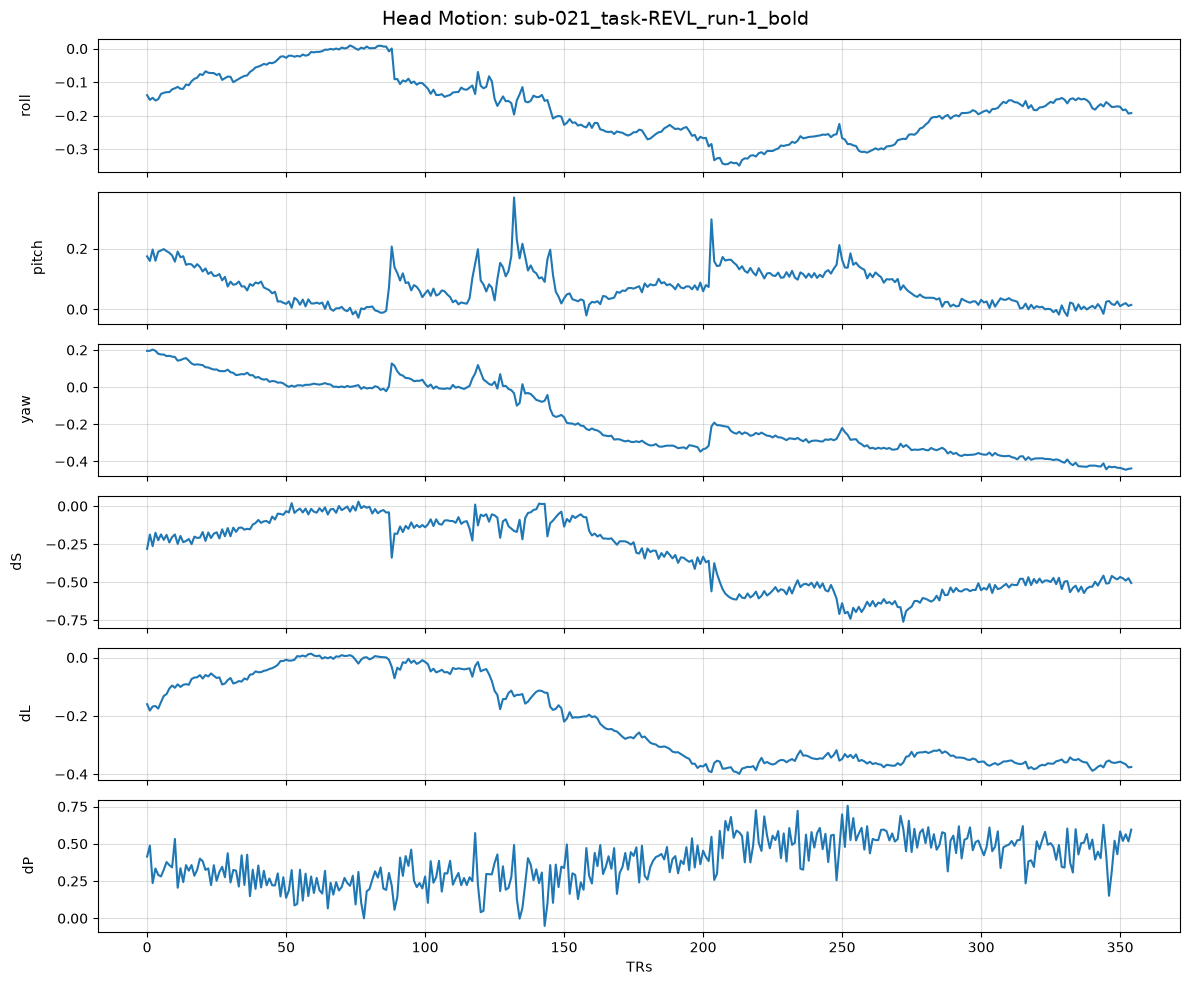

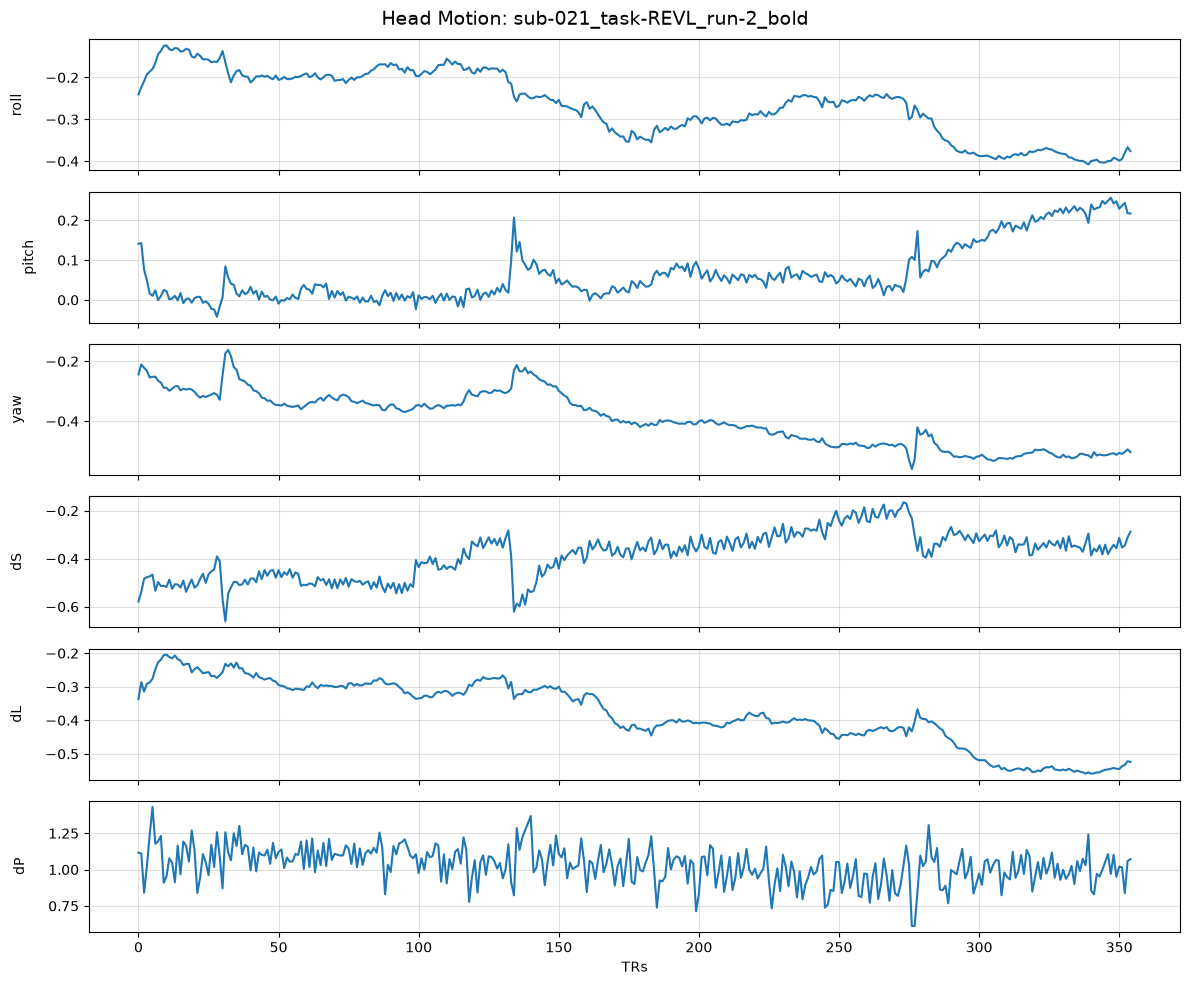

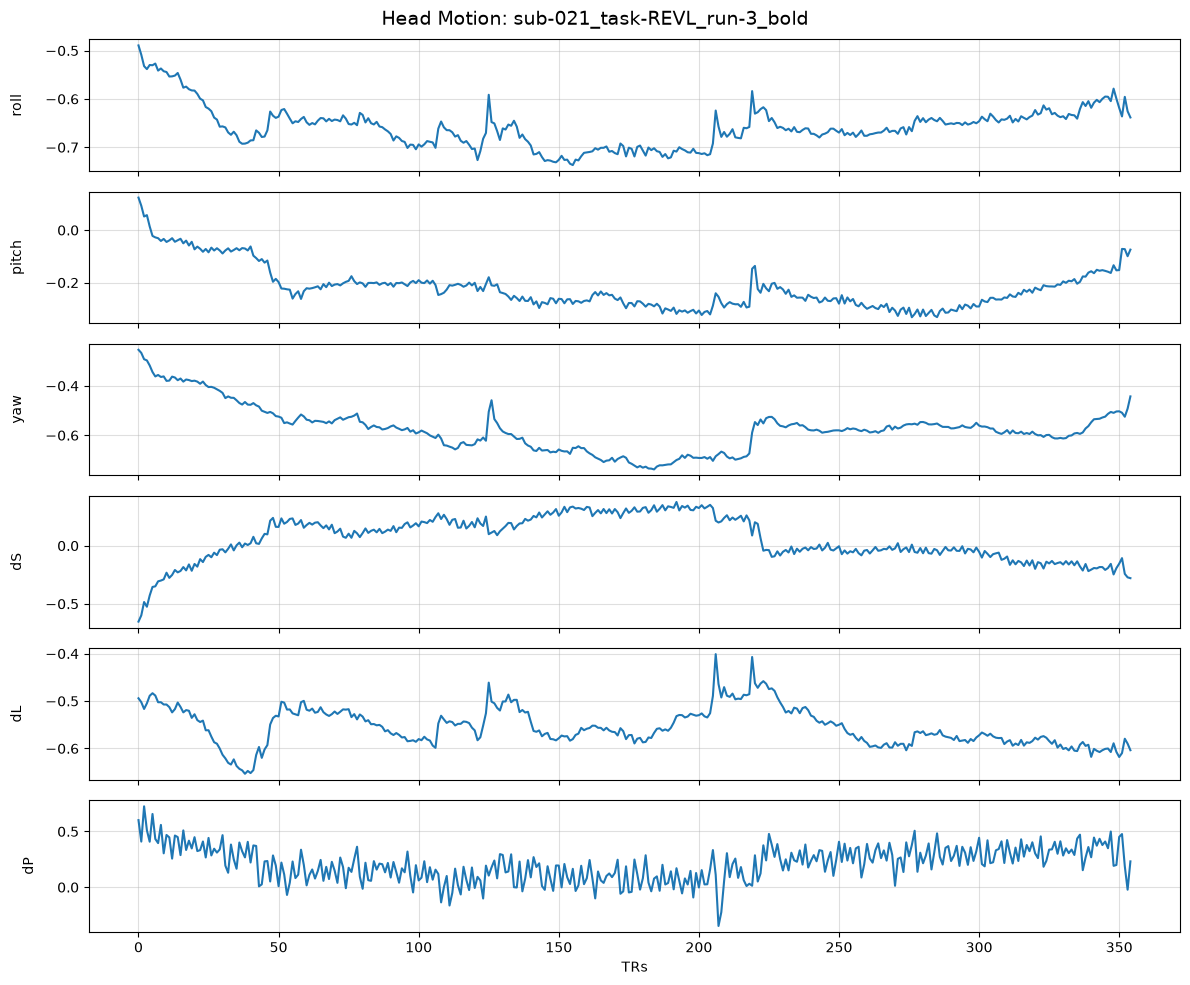

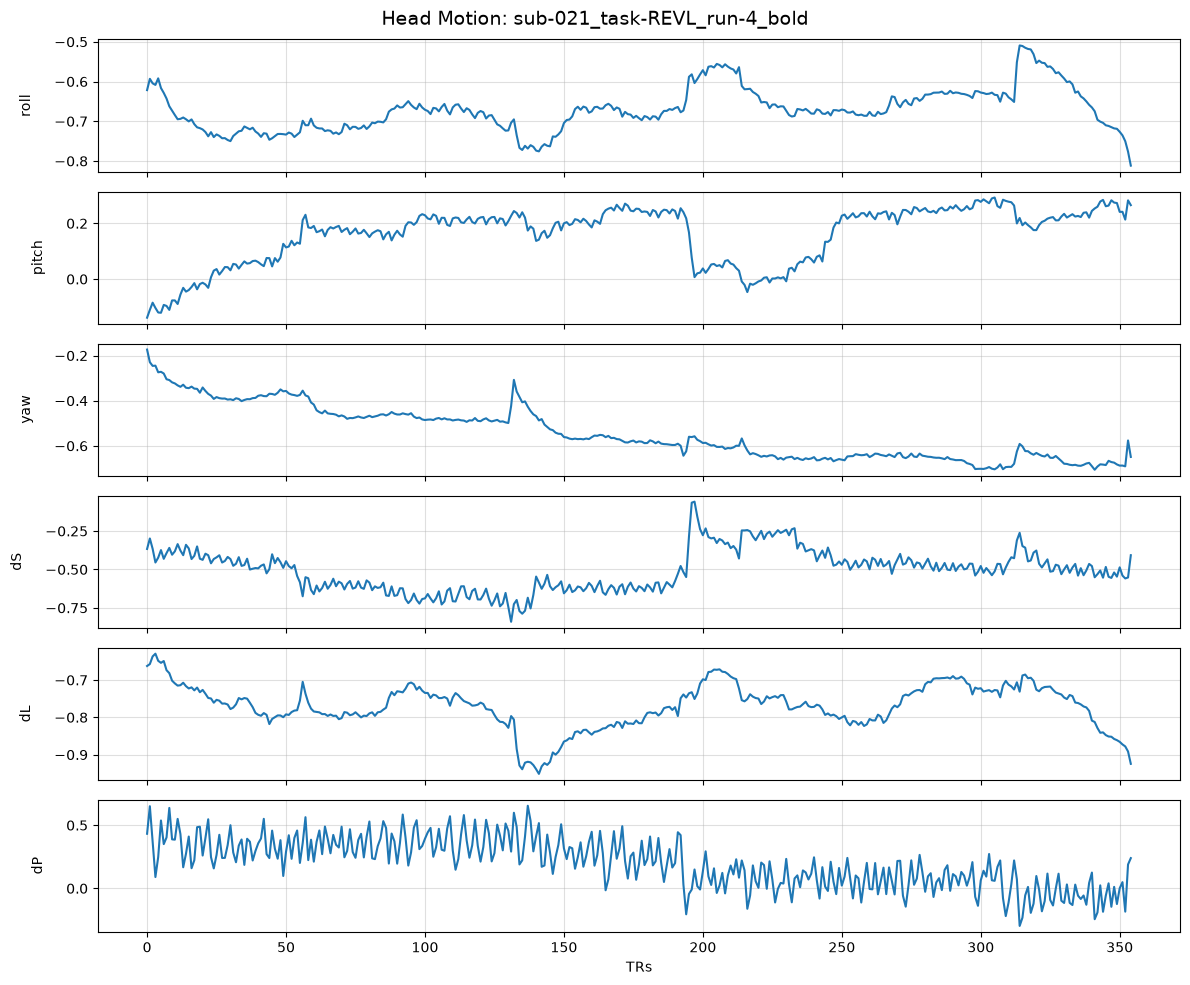

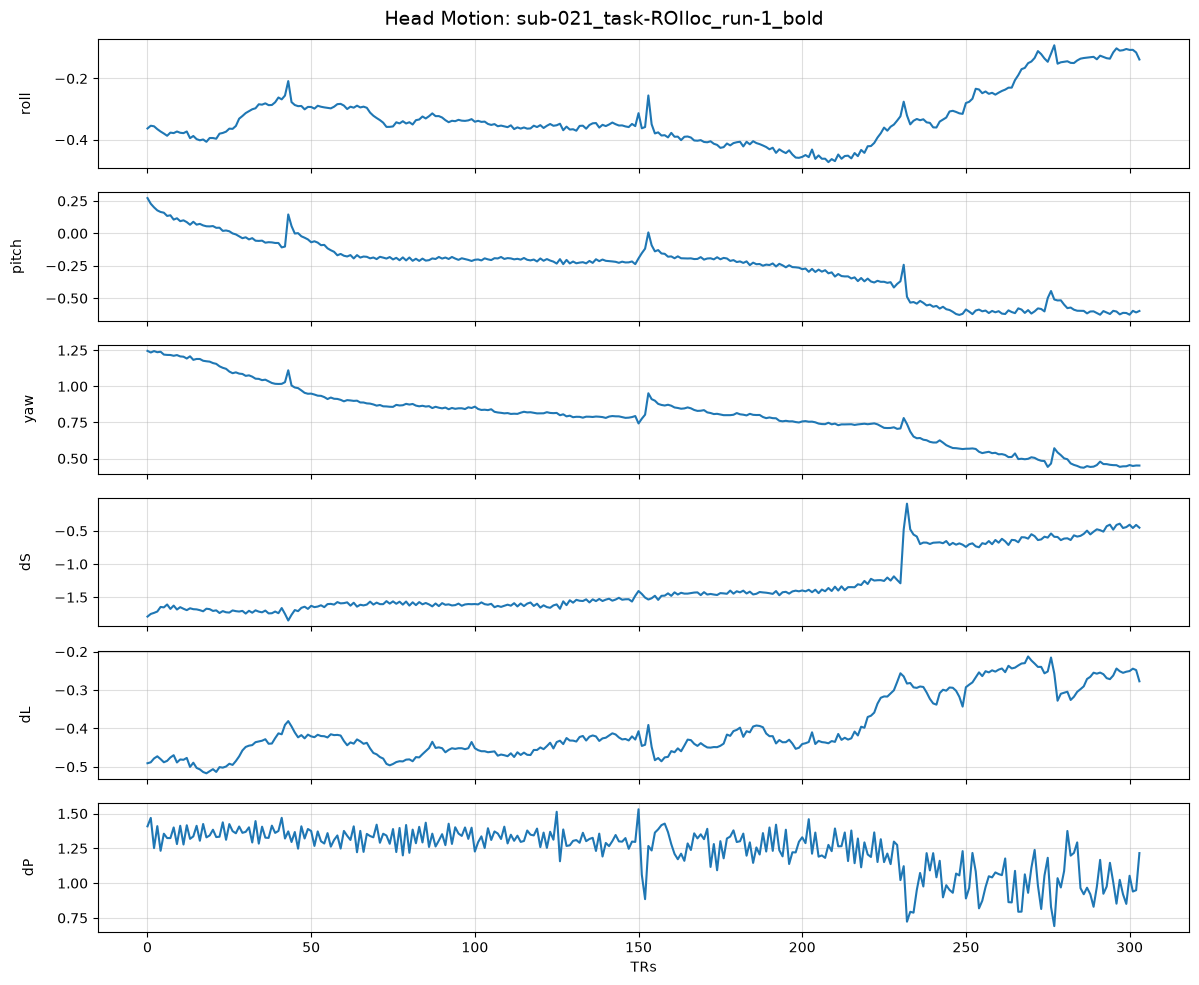

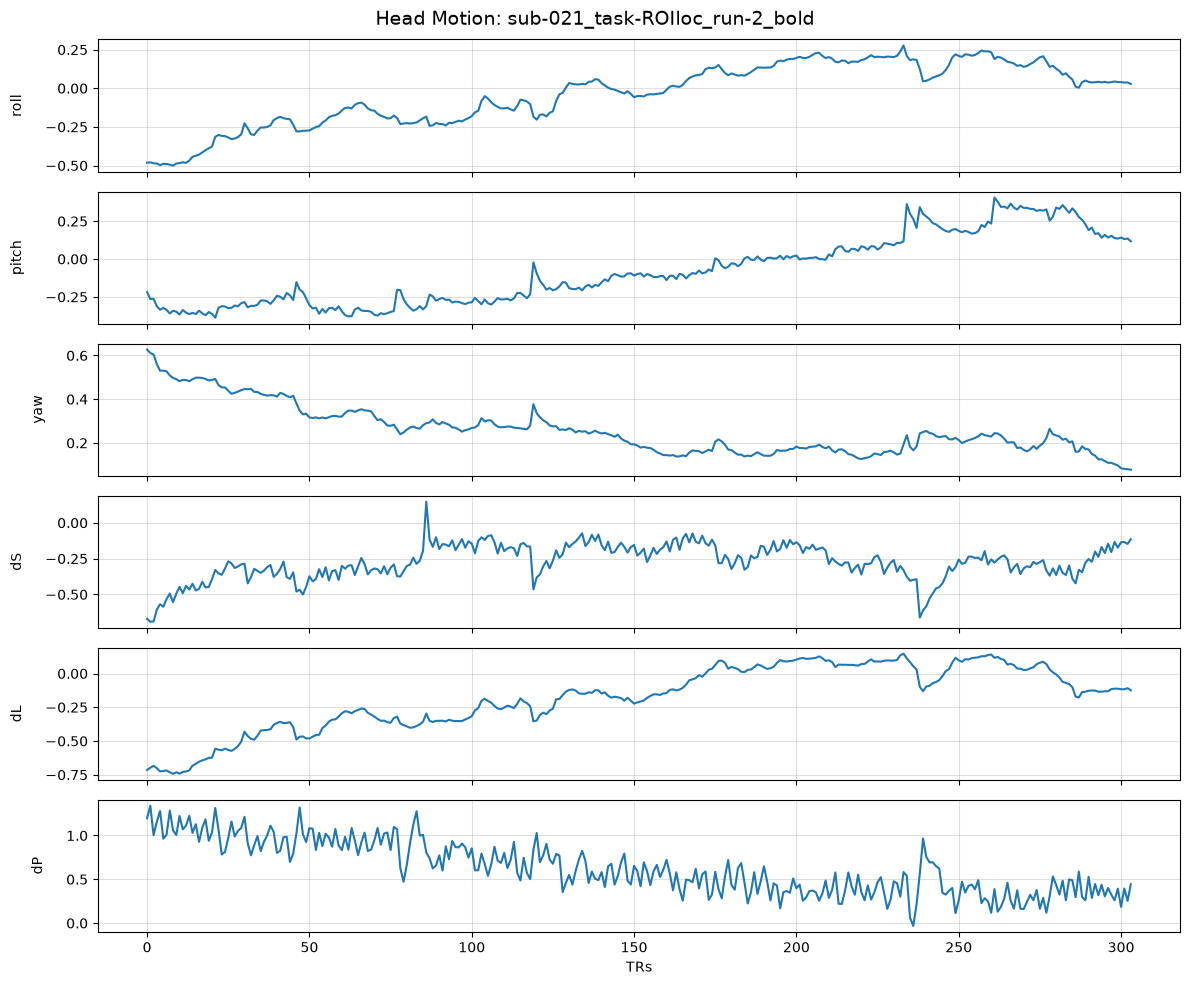

In [6]:
## PLOT THE MOTION PARAMETERS FOR EACH FUNCTIONAL RUN USING MATPLOTLIB

# Define motion output directory
motion_dir = os.path.join(base_dir,f'derivatives/preproc/sub-{sid[0]}/motion')

# Find all motion parameter files
study_motion_files = sorted(
    glob(motion_dir + '/_volreg*/*.1D'))

# Keep motion parameter files and exclude affine matrix files
motion_files = [f for f in study_motion_files
    if 'aff12' not in f]

print("Number of motion files:", len(motion_files))

# Motion parameter names
motion_labels = ['roll', 'pitch', 'yaw', 'dS', 'dL', 'dP']

# Plot each functional run
for motion_file in motion_files:

    motion = np.loadtxt(motion_file)
    run_name = os.path.basename(motion_file).replace('.1D', '')

    fig, axes = plt.subplots(
        6, 1,
        figsize=(12, 10),
        sharex=True)

    for i in range(6):

        axes[i].plot(motion[:, i])

        axes[i].set_ylabel(
            motion_labels[i],
            rotation=90,
            labelpad=15)

        axes[i].grid(True, alpha=0.4)

    axes[-1].set_xlabel('TRs')

    fig.suptitle(
        f'Head Motion: {run_name}',
        fontsize=14)

    plt.tight_layout()
    plt.show()

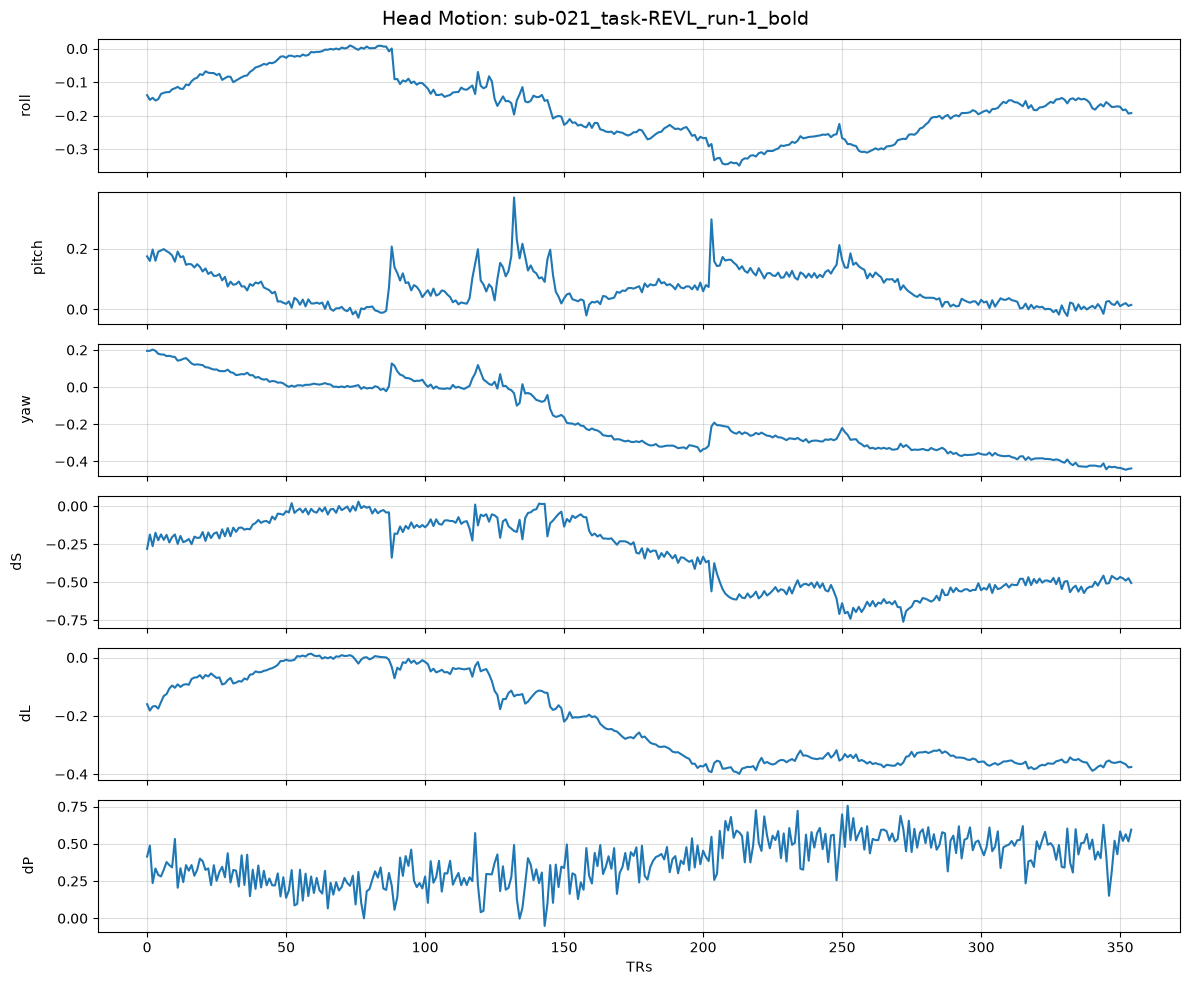

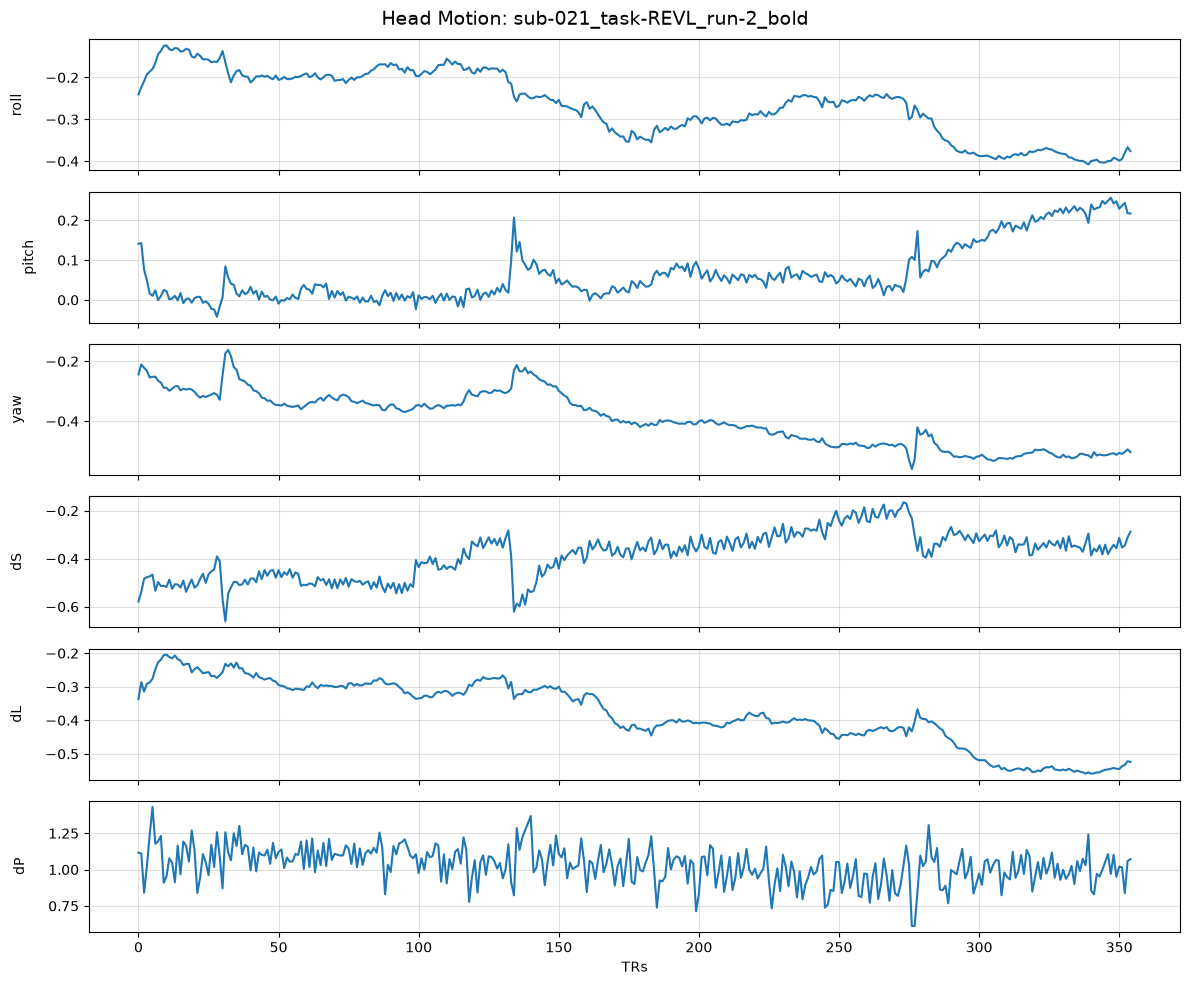

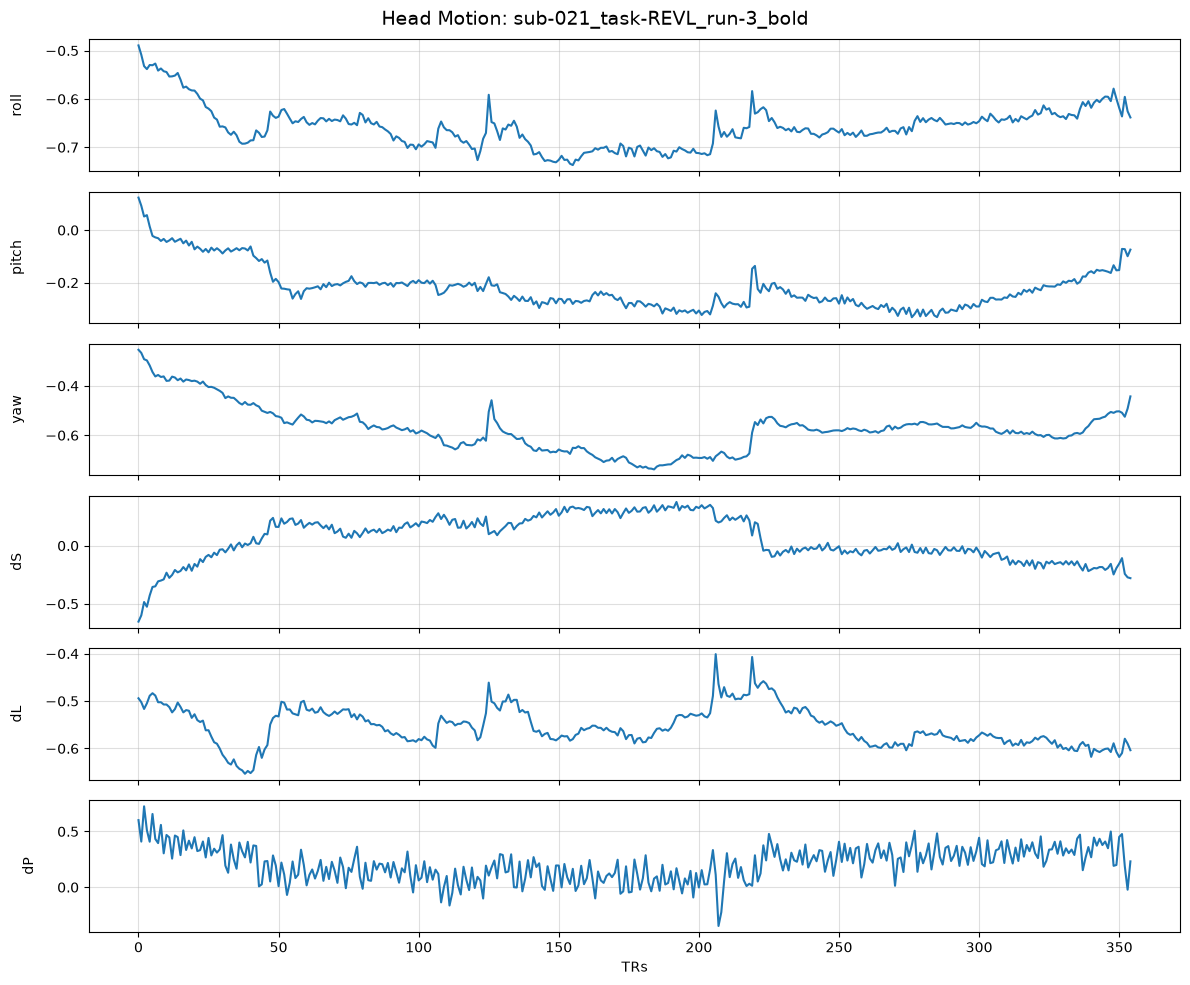

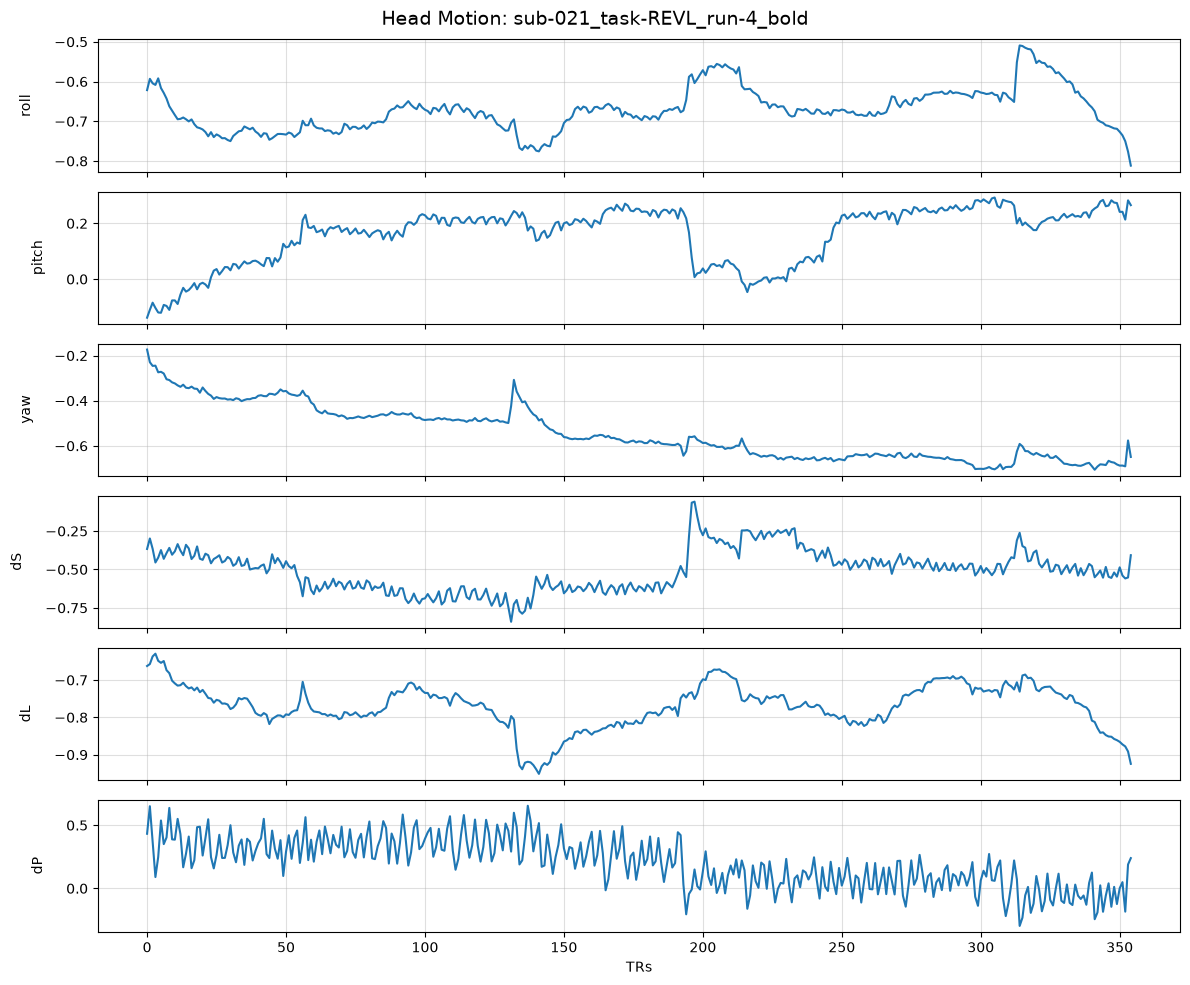

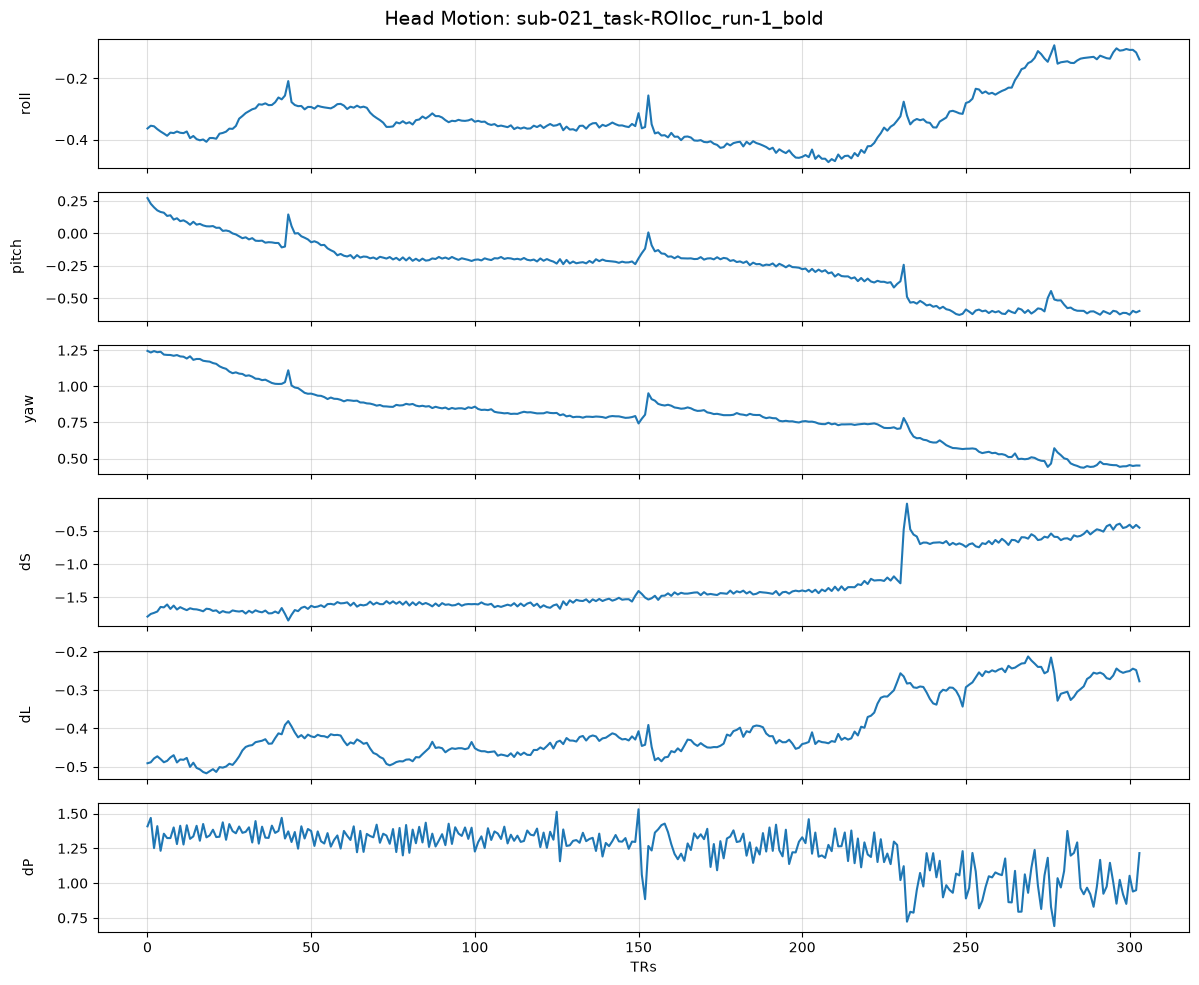

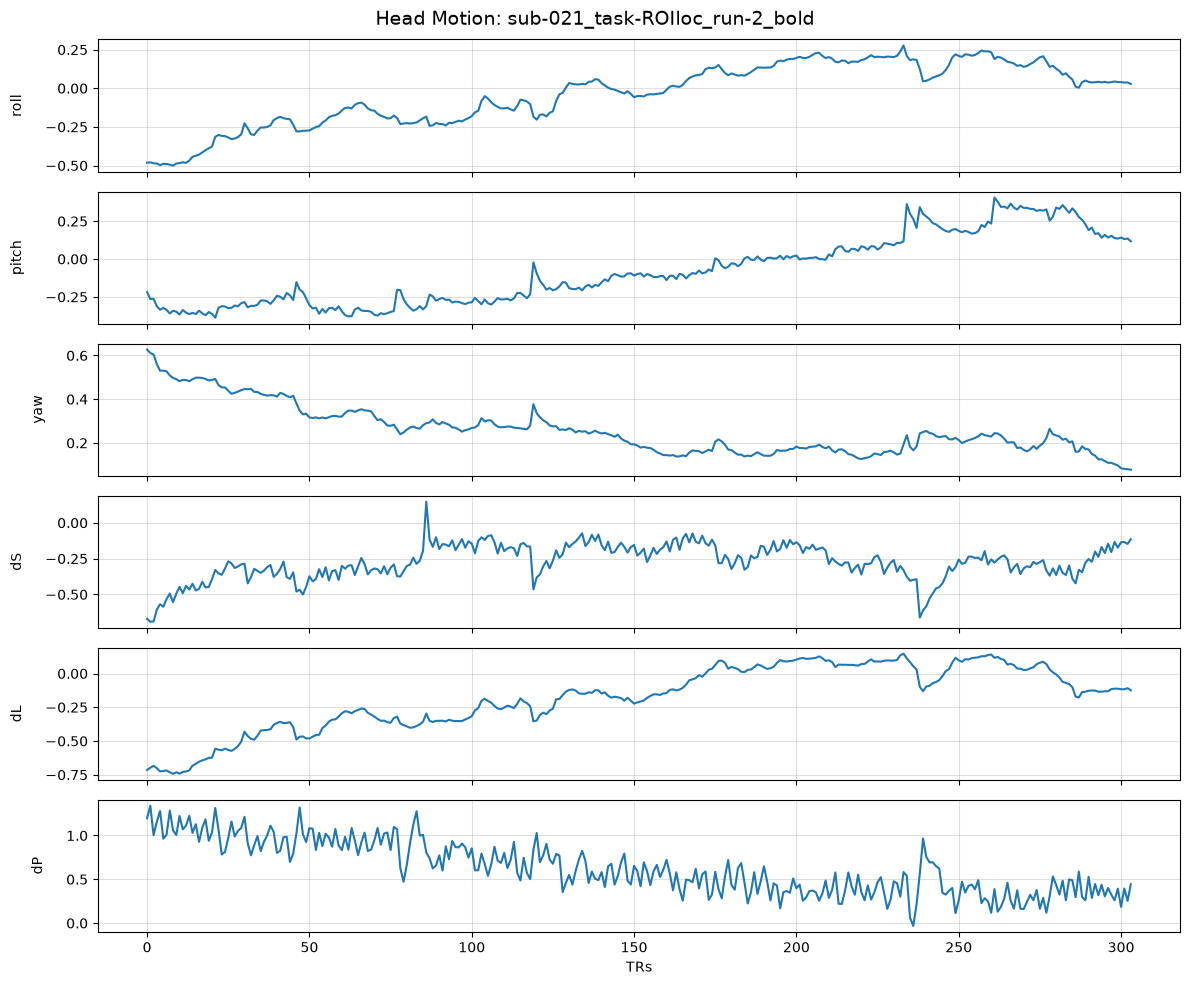

In [7]:
# PLOT THE MOTION PARAMETERS FOR EACH FUNCTIONAL RUN USING SEABORN

import seaborn as sns
import pandas as pd

motion_labels = ['roll', 'pitch', 'yaw', 'dS', 'dL', 'dP']

for motion_file in motion_files:

    motion = np.loadtxt(motion_file)
    run_name = os.path.basename(motion_file).replace('.1D', '')

    motion_df = pd.DataFrame(
        motion,
        columns=motion_labels )

    motion_df['TRs'] = np.arange(len(motion_df))

    fig, axes = plt.subplots(
        6, 1,
        figsize=(12, 10),
        sharex=True)

    for i, parameter in enumerate(motion_labels):

        sns.lineplot(
            data=motion_df,
            x='TRs',
            y=parameter,
            ax=axes[i])

        axes[i].set_ylabel(
            parameter,
            rotation=90,
            labelpad=15 )

        axes[i].set_xlabel('')
        axes[i].grid(True, alpha=0.4)

    axes[-1].set_xlabel('TRs')

    fig.suptitle(
        f'Head Motion: {run_name}',
        fontsize=14)

    plt.tight_layout()
    plt.show()

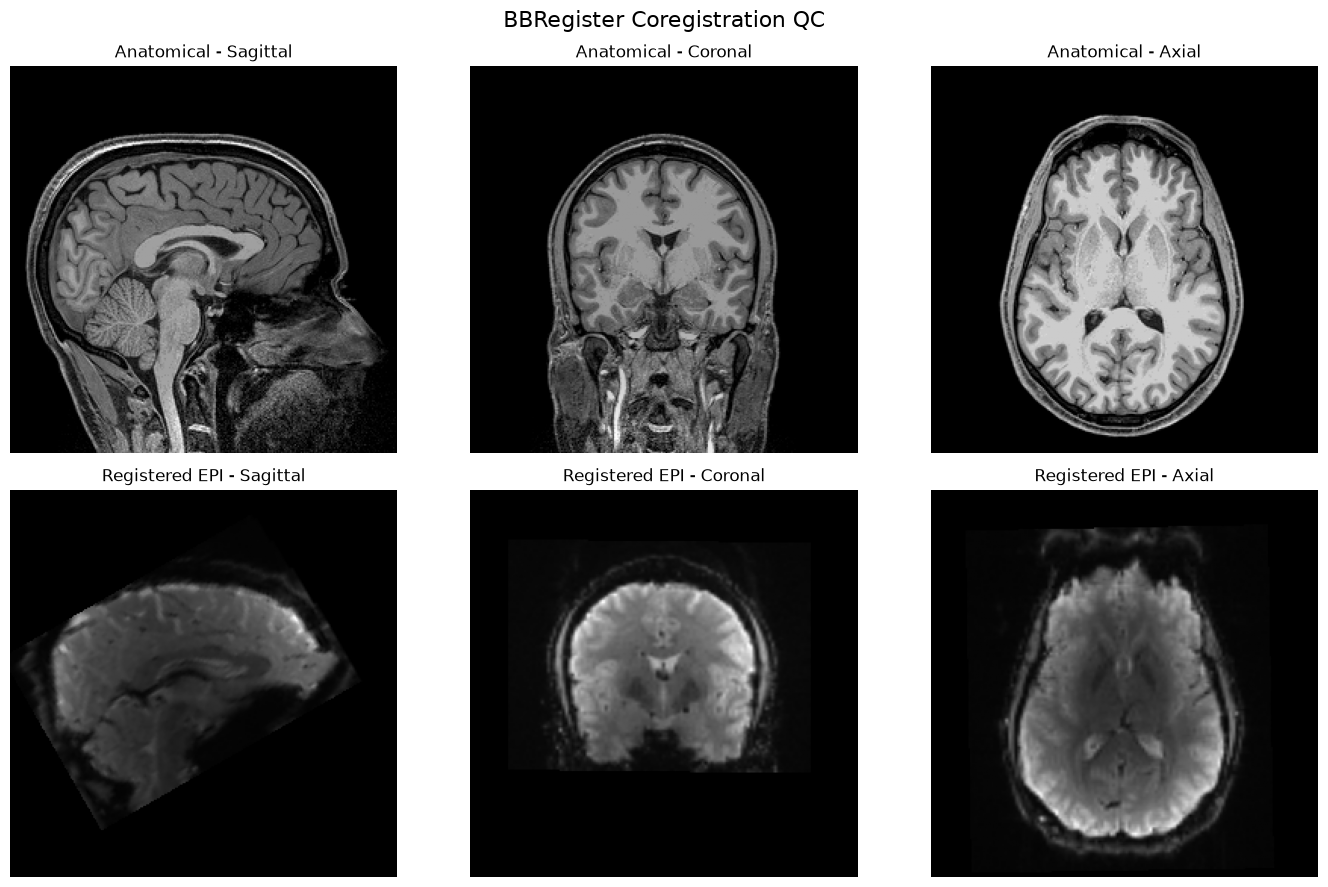

In [12]:
# Coregistration QC

# Paths
coreg_dir = os.path.join( base_dir,  f'derivatives/preproc/sub-{sid[0]}/coreg')

registered_epi_file = os.path.join(coreg_dir,f'sub-{sid[0]}_task-REVL_run-1_bold_roi_bbreg.nii.gz')

# FreeSurfer anatomical image
anat_file = os.path.join(base_dir, f'derivatives/freesurfer/sub-{sid[0]}/mri/T1.mgz')

# Load images
epi_img = nb.load(registered_epi_file)
anat_img = nb.load(anat_file)

# Reorient both images to canonical RAS orientation
epi_img = nb.as_closest_canonical(epi_img)
anat_img = nb.as_closest_canonical(anat_img)

epi = epi_img.get_fdata()
anat = anat_img.get_fdata()

# Middle slices
epi_x = epi.shape[0] // 2
epi_y = epi.shape[1] // 2
epi_z = epi.shape[2] // 2

anat_x = anat.shape[0] // 2
anat_y = anat.shape[1] // 2
anat_z = anat.shape[2] // 2

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

# Anatomical image
axes[0,0].imshow(anat[anat_x, :, :].T, cmap='gray', origin='lower')
axes[0,0].set_title('Anatomical - Sagittal')

axes[0,1].imshow(anat[:, anat_y, :].T, cmap='gray', origin='lower')
axes[0,1].set_title('Anatomical - Coronal')

axes[0,2].imshow(anat[:, :, anat_z].T, cmap='gray', origin='lower')
axes[0,2].set_title('Anatomical - Axial')

# Registered EPI
axes[1,0].imshow(epi[epi_x, :, :].T, cmap='gray', origin='lower')
axes[1,0].set_title('Registered EPI - Sagittal')

axes[1,1].imshow(epi[:, epi_y, :].T, cmap='gray', origin='lower')
axes[1,1].set_title('Registered EPI - Coronal')

axes[1,2].imshow(epi[:, :, epi_z].T, cmap='gray', origin='lower')
axes[1,2].set_title('Registered EPI - Axial')

for ax in axes.flatten():
    ax.axis('off')

plt.suptitle('BBRegister Coregistration QC', fontsize=16)
plt.tight_layout()
plt.show()

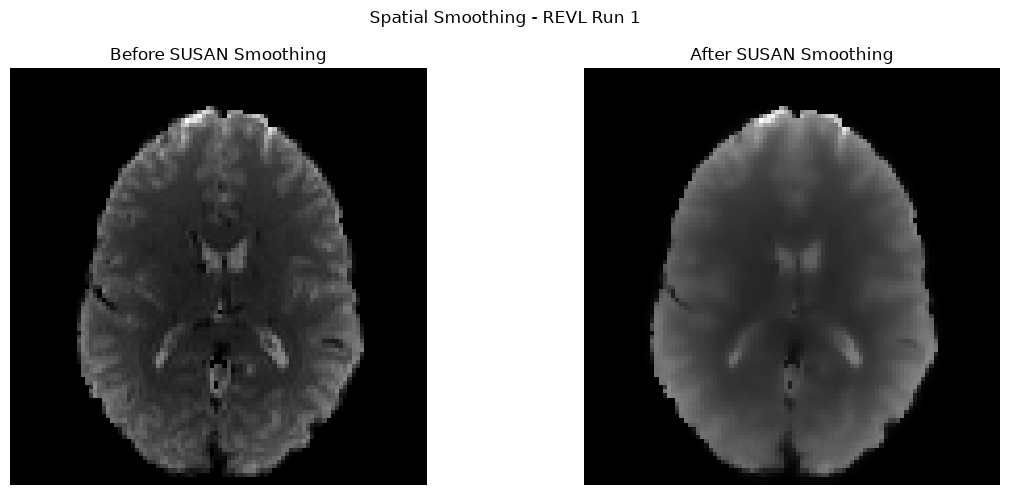

In [13]:
# Spatial Smoothing Visualization - REVL Run 1

func_dir = os.path.join(base_dir, f'derivatives/preproc/sub-{sid[0]}/func')

# Before smoothing
unsmoothed_file = os.path.join(func_dir,   '_maskfunc0', f'sub-{sid[0]}_task-REVL_run-1_bold_volreg_tshift_masked.nii.gz')

# After SUSAN smoothing
smoothed_file = os.path.join(func_dir,'_susan0', f'sub-{sid[0]}_task-REVL_run-1_bold_volreg_tshift_masked_smooth.nii.gz')

# Load images
unsmoothed_img = nb.as_closest_canonical(nb.load(unsmoothed_file))
smoothed_img = nb.as_closest_canonical(nb.load(smoothed_file))

unsmoothed = unsmoothed_img.get_fdata()
smoothed = smoothed_img.get_fdata()

# Choose one volume from the 4D fMRI data
volume = 0

# Choose middle axial slice
z = unsmoothed.shape[2] // 2

# Display the same slice before and after smoothing
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    unsmoothed[:, :, z, volume].T,
    cmap='gray',
    origin='lower')
axes[0].set_title('Before SUSAN Smoothing')
axes[0].axis('off')

axes[1].imshow(
    smoothed[:, :, z, volume].T,
    cmap='gray',
    origin='lower')
axes[1].set_title('After SUSAN Smoothing')
axes[1].axis('off')

plt.suptitle('Spatial Smoothing - REVL Run 1')
plt.tight_layout()
plt.show()

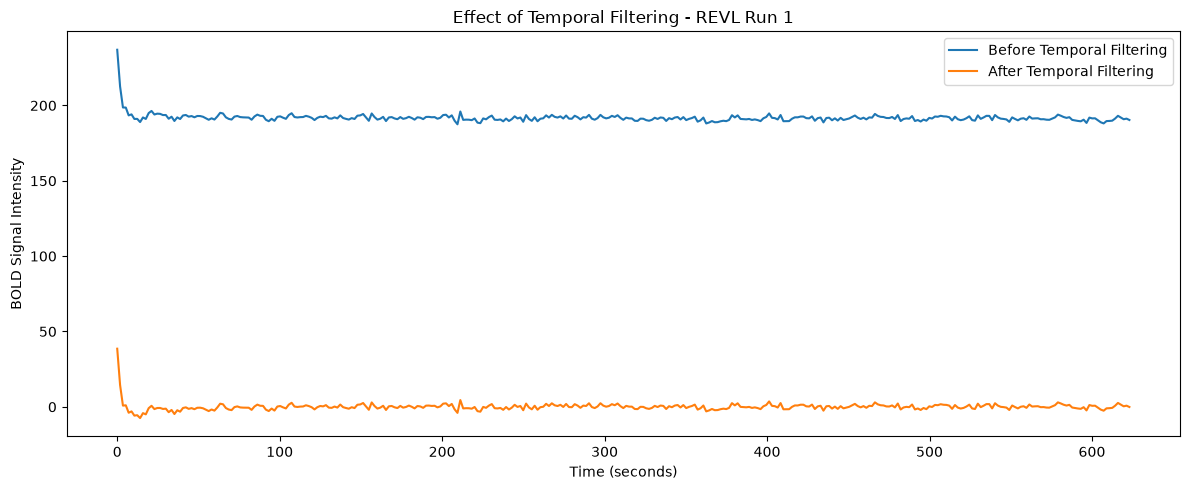

In [14]:
# Temporal Filtering Visualization - REVL Run 1

func_dir = os.path.join( base_dir,f'derivatives/preproc/sub-{sid[0]}/func')

# Before temporal filtering
before_filter_file = os.path.join( func_dir, '_susan0',f'sub-{sid[0]}_task-REVL_run-1_bold_volreg_tshift_masked_smooth.nii.gz')

# After temporal filtering
after_filter_file = os.path.join( func_dir, '_temporal_filter0', f'sub-{sid[0]}_task-REVL_run-1_bold_volreg_tshift_masked_smooth_tempfilt.nii.gz')

# Load 4D fMRI data
before_filter = nb.load(before_filter_file).get_fdata()
after_filter = nb.load(after_filter_file).get_fdata()

# Select a voxel near the center of the brain
x = before_filter.shape[0] // 2
y = before_filter.shape[1] // 2
z = before_filter.shape[2] // 2

# Extract BOLD time series from the same voxel
before_ts = before_filter[x, y, z, :]
after_ts = after_filter[x, y, z, :]

# Create time axis using TR = 1.76 seconds
TR = 1.76
time = np.arange(len(before_ts)) * TR

# Plot before and after temporal filtering
plt.figure(figsize=(12, 5))

plt.plot(
    time,
    before_ts,
    label='Before Temporal Filtering')

plt.plot(
    time,
    after_ts,
    label='After Temporal Filtering')

plt.xlabel('Time (seconds)')
plt.ylabel('BOLD Signal Intensity')
plt.title('Effect of Temporal Filtering - REVL Run 1')
plt.legend()
plt.tight_layout()
plt.show()